# Самостоятельная работа. Слова и их соседи: новости и Пушкин

**Тема:** векторные представления слов (лекция 4). **Данные:** новости Lenta.ru (`data/lenta_ru_2000.jsonl` и `data/lenta_ru_short.jsonl`) и стихотворные тексты А. С. Пушкина (`data/pushkin.txt`).

## Цель

Обучить векторы слов на двух очень разных корпусах и посмотреть, что они знают о словах. Гипотеза дистрибутивности утверждает, что слово определяется своим окружением. Отсюда следует, что у одного и того же слова в новостях и в стихах будут разные соседи. Работа проверяет это на опыте.

## План

| Часть | Содержание |
|---|---|
| 1 | Два корпуса и их подготовка |
| 2 | Модель word2vec на новостях: соседи слов и карта |
| 3 | Задания для самостоятельного решения |

Части 1 и 2 разобраны полностью. В части 3 шесть заданий с самопроверкой.

## Обозначения

- $\mathbf v_w$ обозначает вектор слова $w$ (эмбеддинг).
- Близость двух слов измеряется косинусом угла между их векторами: $\cos(\mathbf v_a,\mathbf v_b)=\dfrac{\mathbf v_a\cdot\mathbf v_b}{\lVert\mathbf v_a\rVert\,\lVert\mathbf v_b\rVert}$. Значение 1 означает одинаковое направление, значение 0 означает отсутствие связи.
- Соседями слова называются слова с наибольшей косинусной близостью к нему.

In [1]:
import json
import math
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100", "#e34948"]
MUTED, GRID = "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})

## Часть 1. Два корпуса

Модель word2vec обучается на предложениях: контекстом слова служат его соседи по предложению. Новости делятся на предложения по точкам, у Пушкина предложением считается строка.

Слова приводятся к начальной форме библиотекой `pymorphy3`. Стоп-слова не удаляются: служебные слова входят в окружение и помогают модели. Подготовка занимает около минуты.

In [2]:
import pymorphy3


def find_data(name):
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / "data" / name).exists():
            return parent / "data" / name
    raise FileNotFoundError(f"Файл data/{name} не найден в репозитории")


morph = pymorphy3.MorphAnalyzer()
_cache = {}


def lemmas(text):
    out = []
    for t in re.findall(r"[а-яё]+", text.lower()):
        if t not in _cache:
            _cache[t] = morph.parse(t)[0].normal_form.replace("ё", "е")
        out.append(_cache[t])
    return out


news_texts = []
for name in ("lenta_ru_2000.jsonl", "lenta_ru_short.jsonl"):
    for line in open(find_data(name), encoding="utf-8"):
        r = json.loads(line)
        news_texts.append((r["title"] + ". " + r["text"]).replace("\xa0", " "))
news_docs = [lemmas(t) for t in news_texts]                                   # новость целиком, для задания 1
news_sents = [s for t in news_texts for s in (lemmas(p) for p in re.split(r"[.!?]+", t)) if len(s) >= 3]

pushkin_lines = [l for l in open(find_data("pushkin.txt"), encoding="utf-8").read().split("\n") if l.strip()]
pushkin_sents = [s for s in (lemmas(l) for l in pushkin_lines) if len(s) >= 2]

for name, sents in [("Новости", news_sents), ("Пушкин", pushkin_sents)]:
    n_tokens = sum(map(len, sents))
    print(f"{name}: предложений {len(sents)}, слов {n_tokens}, разных слов {len(set(w for s in sents for w in s))}")
print("Пример предложения из новостей:", news_sents[10][:12])
print("Пример строки Пушкина:", pushkin_sents[1000])

Новости: предложений 48284, слов 628007, разных слов 32393
Пушкин: предложений 23032, слов 104939, разных слов 11687
Пример предложения из новостей: ['тренер', 'трижды', 'побеждать', 'в', 'чемпионат', 'германия', 'два', 'раз', 'с', 'бавария', 'и', 'один']
Пример строки Пушкина: ['он', 'бежать', 'себя', 'в', 'волна']


## Часть 2. Модель word2vec на новостях

Используется вариант Skip-gram с negative sampling: по слову модель учится отличать его настоящих соседей по окну от случайных слов. Основные параметры:

- `vector_size=100` задаёт размерность вектора слова.
- `window=5` задаёт ширину окна: по пять слов слева и справа.
- `min_count=5` отбрасывает слова, встретившиеся менее пяти раз: для них статистики недостаточно.
- `sg=1` включает Skip-gram, `negative=5` задаёт число случайных слов на одну настоящую пару.
- `epochs=10` задаёт число проходов по корпусу. `workers=1` и `seed` делают результат воспроизводимым.

In [3]:
from gensim.models import Word2Vec


def train_w2v(sentences, min_count=5, window=5, epochs=10):
    return Word2Vec(sentences, vector_size=100, window=window, min_count=min_count, sg=1, negative=5, epochs=epochs,
                    seed=SEED, workers=1)


w2v_news = train_w2v(news_sents)
print("Слов в словаре модели:", len(w2v_news.wv))


def neighbours(model, word, n=8):
    return [w for w, _ in model.wv.most_similar(word, topn=n)]


table = pd.DataFrame({w: neighbours(w2v_news, w) for w in ["нефть", "матч", "фильм", "ученый", "президент"]})
display(table)

Слов в словаре модели: 10086


,нефть,матч,фильм,ученый,президент
0,баррель,розыгрыш,картина,исследователь,глава
1,добыча,встреча,мультфильм,астроном,назарбаев
2,фьючерс,бундеслига,комедия,биолог,председатель
3,сырье,кэнакс,драма,археолог,нурсултан
4,фьючерсный,послематчевый,лента,антрополог,госсекретарь
5,цена,вильярреал,комедийный,выяснить,вица
6,опек,гостевой,боевик,собранный,янукович
7,экспорт,товарищеский,трилогия,находка,советник


**Что видно в таблице.** В столбце под каждым словом стоят его восемь ближайших соседей. Модели никто не сообщал, что «нефть» связана с ценами и баррелями: она вывела это из того, какие слова стоят рядом в предложениях.

Векторы имеют 100 измерений. Чтобы увидеть их расположение, векторы 20 слов из четырёх областей проецируются на плоскость методом главных компонент.

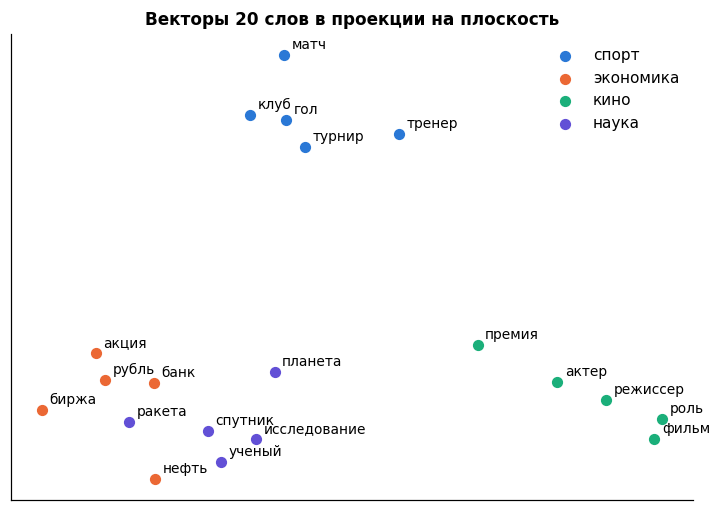

In [4]:
from sklearn.decomposition import PCA

groups = {"спорт": ["матч", "гол", "тренер", "клуб", "турнир"],
          "экономика": ["банк", "нефть", "рубль", "акция", "биржа"],
          "кино": ["фильм", "режиссер", "актер", "роль", "премия"],
          "наука": ["ученый", "спутник", "ракета", "планета", "исследование"]}
words = [w for ws in groups.values() for w in ws]
xy = PCA(n_components=2, random_state=SEED).fit_transform(np.array([w2v_news.wv[w] for w in words]))

fig, ax = plt.subplots(figsize=(8, 5.5))
i = 0
for (name, ws), col in zip(groups.items(), CAT):
    pts = xy[i:i + len(ws)]
    ax.scatter(pts[:, 0], pts[:, 1], color=col, s=40, label=name)
    for (x, y), w in zip(pts, ws):
        ax.annotate(w, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=9)
    i += len(ws)
ax.legend(frameon=False); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Векторы 20 слов в проекции на плоскость")
plt.show()

**Что видно на рисунке.** Слова одной области собрались рядом, области отделены друг от друга. Проекция на плоскость теряет часть сведений, поэтому точные расстояния нужно считать по исходным векторам.

## Часть 3. Задания для самостоятельного решения

Замените многоточия своим кодом. После каждого задания запишите вывод в одну-две фразы. В заданиях используются объекты из частей 1 и 2: `news_docs`, `news_sents`, `pushkin_sents`, функции `lemmas`, `train_w2v`, `neighbours`, модель `w2v_news`.

### Задание 1. PMI вручную

Поточечная взаимная информация сравнивает, как часто два слова встречаются вместе, с тем, как часто они встречались бы при независимости:

$$\mathrm{PMI}(a,b)=\ln\frac{P(a,b)}{P(a)\,P(b)}.$$

Вероятности оцените по новостям: $P(a)$ равна доле новостей, в которых есть слово $a$, $P(a,b)$ равна доле новостей, в которых есть оба слова. Используйте список `news_docs`.

Напишите функцию `pmi(a, b)` и посчитайте её для пар («нефть», «баррель»), («матч», «счет»), («нефть», «матч»).

**Самопроверка.** Для первых двух пар PMI больше 1. Для третьей пары PMI отрицательна или слова вместе не встречаются.

In [ ]:
doc_sets = [set(d) for d in news_docs]
N = len(doc_sets)


def pmi(a, b):
    ...


for a, b in [("нефть", "баррель"), ("матч", "счет"), ("нефть", "матч")]:
    print(a, b, pmi(a, b))

### Задание 2. Соседи и близость

1. Выведите по восемь соседей слов «банк» и «театр» и ещё трёх слов по своему выбору.
2. Посчитайте косинусную близость (`w2v_news.wv.similarity`) для пар («банк», «кредит»), («банк», «футболист»), («театр», «спектакль»), («театр», «нефть»).
3. Найдите слово, соседи которого показались неожиданными, и объясните их по текстам новостей.

**Самопроверка.** Близость пары («банк», «кредит») больше, чем пары («банк», «футболист»), не менее чем на 0.2. То же верно для пар со словом «театр».

In [ ]:
for w in ["банк", "театр", ...]:
    print(w, neighbours(w2v_news, w))

for a, b in [("банк", "кредит"), ("банк", "футболист"), ("театр", "спектакль"), ("театр", "нефть")]:
    print(a, b, ...)

### Задание 3. Лишнее слово

Метод `w2v_news.wv.doesnt_match(список)` возвращает слово, вектор которого дальше всего от среднего вектора списка.

1. Проверьте метод на трёх наборах: «матч, гол, тренер, нефть», «фильм, режиссер, актер, рубль», «банк, акция, биржа, спутник».
2. Составьте два своих набора: один, в котором модель находит лишнее слово верно, и один, в котором она ошибается. Объясните ошибку.

**Самопроверка.** В трёх данных наборах лишними оказываются «нефть», «рубль» и «спутник».

In [ ]:
for group in [["матч", "гол", "тренер", "нефть"], ["фильм", "режиссер", "актер", "рубль"], ["банк", "акция", "биржа", "спутник"]]:
    print(group, ...)

### Задание 4. Аналогии

Отношение между словами соответствует направлению в пространстве векторов. Запрос «москва относится к россии, как ? относится к франции» записывается так:

```python
w2v_news.wv.most_similar(positive=["москва", "франция"], negative=["россия"], topn=5)
```

1. Проверьте три аналогии: «россия : москва = франция : ?», «футбол : футболист = хоккей : ?», «фильм : режиссер = песня : ?».
2. Придумайте ещё две аналогии по новостной лексике.
3. Для каждой аналогии укажите, вошёл ли ожидаемый ответ в первые пять слов.

**Самопроверка.** На этом корпусе ожидаемый ответ в первые пять слов обычно не попадает, хотя найденные слова близки к нему по смыслу: для первой аналогии среди них есть «столица» и «город», для второй «игрок», для третьей «музыкант». Объясните, почему на корпусе в 600 тысяч слов аналогии работают хуже, чем в моделях, обученных на миллиардах слов.

In [ ]:
analogies = [("россия", "москва", "франция"), ("футбол", "футболист", "хоккей"), ("фильм", "режиссер", "песня")]
for a, b, c in analogies:
    print(f"{a} : {b} = {c} : ?", ...)

### Задание 5. Корпус меняет соседей

1. Обучите вторую модель на строках Пушкина: `w2v_pushkin = train_w2v(pushkin_sents, min_count=3, epochs=30)`. Корпус в несколько раз меньше, поэтому порог частоты снижен и проходов больше.
2. Для слов «свет», «мир», «золотой», «ключ», «звезда» выведите по восемь соседей в двух моделях.
3. Для каждого слова посчитайте, сколько слов общие у двух списков из десяти соседей.
4. Объясните различия: какое значение слова преобладает в каждом корпусе?

**Самопроверка.** У каждого из пяти слов общих соседей не больше двух из десяти.

In [ ]:
w2v_pushkin = ...
for w in ["свет", "мир", "золотой", "ключ", "звезда"]:
    ...

### Задание 6. Слово вне словаря

Модель word2vec хранит векторы только тех слов, которые видела при обучении. Модель fastText представляет слово суммой векторов его буквенных n-грамм и строит вектор для любого слова.

1. Проверьте, есть ли в словаре `w2v_news` слова «нефтедобытчик», «футболистка», «киноактриса». Что происходит при обращении к вектору отсутствующего слова?
2. Обучите fastText на новостях: `FastText(news_sents, vector_size=100, window=5, min_count=5, sg=1, epochs=5, seed=SEED, workers=1)` из `gensim.models`. Обучение занимает одну-две минуты.
3. Выведите по восемь соседей каждого из трёх слов по модели fastText.
4. Сравните соседей слова «нефть» в двух моделях.

**Самопроверка.** Хотя бы одного из трёх слов нет в словаре word2vec, и обращение к его вектору вызывает ошибку `KeyError`. Модель fastText возвращает соседей для всех трёх слов, среди соседей есть слова с тем же корнем.

In [ ]:
for w in ["нефтедобытчик", "футболистка", "киноактриса"]:
    print(w, w in w2v_news.wv)

from gensim.models import FastText
ft = ...
...

## Что сдавать

Блокнот, который выполняется целиком без ошибок, с решениями шести заданий и выводами.

- [ ] К каждому заданию записан вывод со ссылкой на полученные списки и числа.
- [ ] В заданиях 2, 3 и 4 есть собственные примеры.
- [ ] В задании 5 объяснены различия соседей через значения слов в двух корпусах.
- [ ] Значение `seed` зафиксировано, результат воспроизводится.